# Models without an LLM — wider search

`models.ipynb` tried a few non-LLM models (regex features, mpnet / BERT embeddings) and none beat the
simple reference "predict insufficient for every question" (F1 0.51). This notebook tries many more
options, grouped by the kind of input they use:

| group | input | models tried |
|---|---|---|
| A. one number | a single feature (length, share of common words, technical tokens) | logistic regression = a learned cut-off |
| B. hand-made features | regex cues (`feats.handcrafted`) and writing-style counts (`nonllm_feats.text_stats`) | logistic regression (L2, L1), naive Bayes, k-nearest neighbours, LDA, SVM, random forest, extra trees, gradient boosting |
| C. words | TF-IDF of words or character n-grams, word counts | logistic regression, complement naive Bayes |
| D. sentence embeddings | mpnet / BERT vectors of the full text, the title only, the body only, or title and body side by side | logistic regression, SVM, k-nearest neighbours, LDA, PCA + logistic regression |
| E. combinations | soft vote (average probability) of models from different groups | |

Every model is scored the same way as before (`feats.cv_eval`): 5-fold stratified CV repeated 5 times,
F1 of class 1, with the decision threshold chosen inside each training part only.
`AUC` is computed from the out-of-fold probabilities of the first repeat (0.5 = random ordering).
Text-to-number steps that learn from data (TF-IDF vocabulary, scaling, PCA) sit inside the pipeline,
so they are refit on each training part; the sentence encoders are pretrained and never see labels.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import time, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, VotingClassifier
from sklearn.metrics import f1_score, roc_auc_score
from feats import SEED, handcrafted, cv_eval
from nonllm_feats import text_stats, embed_parts

train, test = pd.read_csv("data/train.csv"), pd.read_csv("data/test.csv")
y, n = train.sufficiency.values, len(train)
texts = np.concatenate([train.text.values, test.text.values])   # train first, then test (same order as the cached embeddings)

H = handcrafted(texts); S = text_stats(texts)
HS = pd.concat([H, S], axis=1)
E = {k: np.load(f"features/emb_{k}.npy") for k in ["mpnet", "bert"]}
for tag, name in [("mpnet", "sentence-transformers/all-mpnet-base-v2"), ("bert", "bert-base-uncased")]:
    E[f"{tag}_title"], E[f"{tag}_body"] = embed_parts(texts, name, tag)
    E[f"{tag}_title+body"] = np.hstack([E[f"{tag}_title"], E[f"{tag}_body"]])
print("hand-made features:", H.shape[1], "+ text stats:", S.shape[1], "| embeddings:", {k: v.shape[1] for k, v in E.items()})
print("reference F1 (predict all insufficient):", round(f1_score(y, np.ones(n)), 3))

W1123 08:17:10.992000 50218 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 7303.51it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 13228.94it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14360.84it/s]


[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


hand-made features: 15 + text stats: 16 | embeddings: {'mpnet': 768, 'bert': 768, 'mpnet_title': 768, 'mpnet_body': 768, 'mpnet_title+body': 1536, 'bert_title': 768, 'bert_body': 768, 'bert_title+body': 1536}
reference F1 (predict all insufficient): 0.512


In [2]:
# Model zoo. Every model ends in predict_proba so the same CV routine can tune its threshold.
def lr(C=1.0, penalty="l2"):
    return LogisticRegression(C=C, penalty=penalty, solver="liblinear", class_weight="balanced", random_state=SEED)
def scaled(m): return make_pipeline(StandardScaler(), m)

TABULAR = {
    "LR C=0.1":            scaled(lr(0.1)),
    "LR L1 C=0.3":         scaled(lr(0.3, "l1")),          # L1 keeps only a few features
    "Gaussian naive Bayes": scaled(GaussianNB()),
    "kNN k=7":             scaled(KNeighborsClassifier(7, weights="distance")),
    "LDA (shrinkage)":     LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "SVM RBF":             scaled(SVC(C=1, class_weight="balanced", probability=True, random_state=SEED)),
    "random forest":       RandomForestClassifier(300, max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=SEED),
    "extra trees":         ExtraTreesClassifier(300, max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=SEED),
    "gradient boosting":   GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, subsample=0.8, random_state=SEED),
}
EMBEDDING = {
    "LR C=0.1":        lr(0.1),
    "LR C=1":          lr(1.0),
    "SVM RBF":         SVC(C=1, class_weight="balanced", probability=True, random_state=SEED),
    "kNN k=7 cosine":  KNeighborsClassifier(7, metric="cosine", weights="distance"),
    "LDA (shrinkage)": LinearDiscriminantAnalysis(solver="lsqr", shrinkage="auto"),
    "PCA 10 + LR":     make_pipeline(PCA(10, random_state=SEED), StandardScaler(), lr(0.1)),
}

results, OOF = [], {}
def run(group, inputs, model_name, model, X):
    t0 = time.time()
    r = cv_eval(model, X, y)
    OOF[(group, inputs, model_name)] = r["oof"]
    results.append({"group": group, "input": inputs, "model": model_name, "F1 CV tuned": r["f1_tuned"],
                    "std": r["f1_tuned_std"], "F1 @0.5": r["f1@0.5"], "AUC": roc_auc_score(y, r["oof"]),
                    "sec": time.time() - t0})

## A — one number with a learned cut-off

In [3]:
for col, src in [("log_words", H), ("log_chars", S), ("share_common_words", S), ("n_tech_tokens", S),
                 ("type_token_ratio", S), ("first_person_detail", H)]:
    run("A one number", col, "LR", scaled(lr(1.0)), src[[col]].values[:n])
pd.DataFrame(results).query("group == 'A one number'").round(3)

,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec
0,A one number,log_words,LR,0.448,0.141,0.442,0.575,1.533
1,A one number,log_chars,LR,0.410,0.142,0.469,0.555,1.505
2,A one number,share_common_words,LR,0.510,0.038,0.323,0.457,1.486
3,A one number,n_tech_tokens,LR,0.449,0.129,0.440,0.563,1.478
4,A one number,type_token_ratio,LR,0.530,0.079,0.505,0.652,1.535
5,A one number,first_person_detail,LR,0.483,0.067,0.346,0.467,1.526


## B — hand-made features

In [4]:
for inputs, X in [("regex cues (15)", H.values[:n]), ("text stats (16)", S.values[:n]), ("regex + stats (31)", HS.values[:n])]:
    for name, m in TABULAR.items():
        run("B hand-made", inputs, name, m, X)
pd.DataFrame(results).query("group == 'B hand-made'").sort_values("F1 CV tuned", ascending=False).round(3)

,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec
20,B hand-made,text stats (16),SVM RBF,0.514,0.053,0.020,0.462,1.515
29,B hand-made,regex + stats (31),SVM RBF,0.504,0.051,0.000,0.395,1.544
22,B hand-made,text stats (16),extra trees,0.496,0.102,0.370,0.570,15.150
21,B hand-made,text stats (16),random forest,0.485,0.117,0.452,0.609,19.977
6,B hand-made,regex cues (15),LR C=0.1,0.481,0.076,0.405,0.486,1.507
12,B hand-made,regex cues (15),random forest,0.480,0.117,0.376,0.409,18.353
11,B hand-made,regex cues (15),SVM RBF,0.479,0.097,0.028,0.356,1.524
25,B hand-made,regex + stats (31),LR L1 C=0.3,0.468,0.084,0.425,0.442,1.516
32,B hand-made,regex + stats (31),gradient boosting,0.468,0.114,0.300,0.477,4.183
13,B hand-made,regex cues (15),extra trees,0.467,0.095,0.301,0.381,14.862


## C — words (bag of words / character n-grams)

In [5]:
T = texts[:n]
WORDS = {
    "TF-IDF words 1-2 + LR":        make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), lr(1.0)),
    "TF-IDF words 1-2 + LR C=10":   make_pipeline(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), lr(10.0)),
    "TF-IDF char 2-5 + LR":         make_pipeline(TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True), lr(1.0)),
    "word counts + complement NB":  make_pipeline(CountVectorizer(min_df=2), ComplementNB()),
    "char counts + complement NB":  make_pipeline(CountVectorizer(analyzer="char_wb", ngram_range=(2, 4), min_df=2), ComplementNB()),
    # function words only: HOW something is asked, independent of the product (Outlook, iPhone ...)
    "common-word counts + LR":      make_pipeline(CountVectorizer(vocabulary=sorted(__import__("nonllm_feats").COMMON)),
                                                  FunctionTransformer(lambda X: np.log1p(X.toarray())), StandardScaler(), lr(0.1)),
}
for name, m in WORDS.items():
    run("C words", "text", name, m, T)
pd.DataFrame(results).query("group == 'C words'").sort_values("F1 CV tuned", ascending=False).round(3)

,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec
34,C words,text,TF-IDF words 1-2 + LR C=10,0.536,0.118,0.206,0.600,1.926
33,C words,text,TF-IDF words 1-2 + LR,0.533,0.107,0.283,0.613,1.927
35,C words,text,TF-IDF char 2-5 + LR,0.473,0.124,0.216,0.564,4.283
38,C words,text,common-word counts + LR,0.447,0.133,0.310,0.459,1.690
36,C words,text,word counts + complement NB,0.430,0.164,0.286,0.609,1.653
37,C words,text,char counts + complement NB,0.276,0.202,0.276,0.674,3.493


## D — sentence embeddings

In [6]:
for inputs in ["mpnet", "mpnet_title", "mpnet_body", "mpnet_title+body", "bert", "bert_title", "bert_body", "bert_title+body"]:
    for name, m in EMBEDDING.items():
        run("D embeddings", inputs, name, m, E[inputs][:n])
pd.DataFrame(results).query("group == 'D embeddings'").sort_values("F1 CV tuned", ascending=False).head(15).round(3)

,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec
56,D embeddings,mpnet_body,PCA 10 + LR,0.521,0.110,0.528,0.632,1.629
44,D embeddings,mpnet,PCA 10 + LR,0.496,0.146,0.518,0.603,1.625
83,D embeddings,bert_title+body,SVM RBF,0.491,0.079,0.065,0.500,1.841
86,D embeddings,bert_title+body,PCA 10 + LR,0.491,0.096,0.416,0.555,1.669
69,D embeddings,bert_title,LR C=0.1,0.489,0.066,0.419,0.567,1.517
75,D embeddings,bert_body,LR C=0.1,0.488,0.106,0.377,0.562,1.517
42,D embeddings,mpnet,kNN k=7 cosine,0.485,0.142,0.130,0.578,1.425
71,D embeddings,bert_title,SVM RBF,0.483,0.067,0.026,0.538,1.642
65,D embeddings,bert,SVM RBF,0.483,0.112,0.000,0.400,1.649
63,D embeddings,bert,LR C=0.1,0.482,0.069,0.438,0.613,1.489


## E — combinations (soft vote)

Each member sees only its own columns of one big matrix (hand-made features | BERT | mpnet body), and the
vote averages their probabilities. Members are fixed in advance (one simple model per input type),
not picked from the tables above, so the score is not inflated by choosing the winners.

In [7]:
nh, nb, nm = HS.shape[1], E["bert"].shape[1], E["mpnet_body"].shape[1]
X_all = np.hstack([HS.values, E["bert"], E["mpnet_body"]])[:n]
def cols(a, b): return ColumnTransformer([("keep", "passthrough", list(range(a, b)))])
m_hand = make_pipeline(cols(0, nh), StandardScaler(), lr(0.1))
m_bert = make_pipeline(cols(nh, nh + nb), lr(0.1))
m_mpb = make_pipeline(cols(nh + nb, nh + nb + nm), lr(0.1))
m_rf = make_pipeline(cols(0, nh), RandomForestClassifier(300, max_depth=3, min_samples_leaf=3, class_weight="balanced", random_state=SEED))
for name, members in [("hand-made LR + BERT LR", [m_hand, m_bert]),
                      ("hand-made LR + mpnet body LR", [m_hand, m_mpb]),
                      ("hand-made LR + BERT LR + mpnet body LR", [m_hand, m_bert, m_mpb]),
                      ("hand-made LR + hand-made RF + BERT LR + mpnet body LR", [m_hand, m_rf, m_bert, m_mpb])]:
    run("E vote", "mixed", name, VotingClassifier([(f"m{i}", m) for i, m in enumerate(members)], voting="soft"), X_all)
pd.DataFrame(results).query("group == 'E vote'").round(3)

,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec
87,E vote,mixed,hand-made LR + BERT LR,0.443,0.114,0.395,0.448,2.122
88,E vote,mixed,hand-made LR + mpnet body LR,0.450,0.112,0.394,0.451,2.126
89,E vote,mixed,hand-made LR + BERT LR + mpnet body LR,0.459,0.105,0.394,0.451,2.607
90,E vote,mixed,hand-made LR + hand-made RF + BERT LR + mpnet ...,0.444,0.109,0.434,0.489,19.510


## All non-LLM results

In [8]:
res = pd.DataFrame(results).sort_values("F1 CV tuned", ascending=False)
res["beats all-1 (0.51)"] = res["F1 CV tuned"] > 0.512
res.to_csv("logs/nonllm_results.csv", index=False)
print(f"{len(res)} models tried, {res['beats all-1 (0.51)'].sum()} beat the all-1 reference; "
      f"{(res.AUC >= 0.6).sum()} have AUC >= 0.6")
res.head(20).round(3)

91 models tried, 5 beat the all-1 reference; 9 have AUC >= 0.6


,group,input,model,F1 CV tuned,std,F1 @0.5,AUC,sec,beats all-1 (0.51)
34,C words,text,TF-IDF words 1-2 + LR C=10,0.536,0.118,0.206,0.600,1.926,True
33,C words,text,TF-IDF words 1-2 + LR,0.533,0.107,0.283,0.613,1.927,True
4,A one number,type_token_ratio,LR,0.530,0.079,0.505,0.652,1.535,True
56,D embeddings,mpnet_body,PCA 10 + LR,0.521,0.110,0.528,0.632,1.629,True
20,B hand-made,text stats (16),SVM RBF,0.514,0.053,0.020,0.462,1.515,True
2,A one number,share_common_words,LR,0.510,0.038,0.323,0.457,1.486,False
29,B hand-made,regex + stats (31),SVM RBF,0.504,0.051,0.000,0.395,1.544,False
22,B hand-made,text stats (16),extra trees,0.496,0.102,0.370,0.570,15.150,False
44,D embeddings,mpnet,PCA 10 + LR,0.496,0.146,0.518,0.603,1.625,False
83,D embeddings,bert_title+body,SVM RBF,0.491,0.079,0.065,0.500,1.841,False


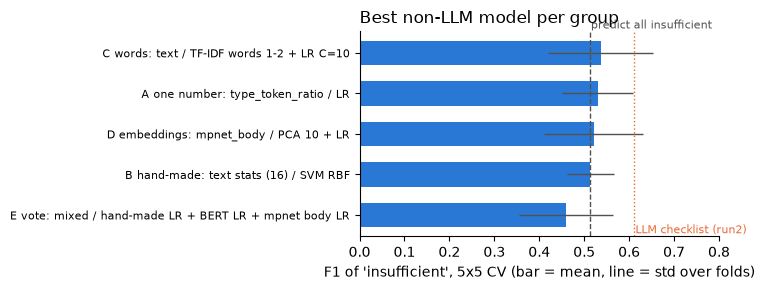

In [9]:
# Best model per group, next to the reference lines
best = res.loc[res.groupby("group")["F1 CV tuned"].idxmax()].sort_values("F1 CV tuned")
fig, ax = plt.subplots(figsize=(7.5, 3))
lab = best.group + ": " + best.input + " / " + best.model
ax.barh(range(len(best)), best["F1 CV tuned"], xerr=best["std"], color="#2a78d6", height=0.6,
        error_kw={"ecolor": "#52514e", "lw": 1})
ax.axvline(0.512, color="#52514e", ls="--", lw=1); ax.text(0.515, len(best) - 0.4, "predict all insufficient", fontsize=8, color="#52514e")
ax.axvline(0.611, color="#eb6834", ls=":", lw=1); ax.text(0.614, -0.45, "LLM checklist (run2)", fontsize=8, color="#eb6834")
ax.set_yticks(range(len(best))); ax.set_yticklabels(lab, fontsize=8)
ax.set_xlim(0, 0.8); ax.set_xlabel("F1 of 'insufficient', 5x5 CV (bar = mean, line = std over folds)")
ax.spines[["top", "right"]].set_visible(False); ax.set_title("Best non-LLM model per group", loc="left")
plt.tight_layout(); plt.show()